# Per-code MFN estimate: pooled 2024 customs AVE vs. USITC HTS statutory rate

**Purpose.** The Section 301 forced-labor Notice of Action caps five economies at
`MFN + 301 = cap` (EU & Taiwan → 10%; Japan, Korea, Switzerland → 12.5%), i.e. the
additive labor-301 charge is `max(0, cap − MFN)` **per HS code**. At go-live this was
shortcut to `MFN = 0`, which charges the full cap on every line — the *maximum* possible
labor-301 — and overstates these five (it flips the EU's Jul-24 step to a small rise where
the FT expects a slight fall).

To implement the cap correctly we need an **MFN rate per HS10 code**. This notebook builds
and compares two independent estimates:

1. **Pooled customs AVE** — `Σduty / Σvalue` over the four *non-FTA* cap countries
   (EU, Japan, Taiwan, Switzerland) in **2024** (pre-trade-war, so duties ≈ MFN;
   Korea excluded because KORUS depresses its applied rate below MFN). Stays in the
   `duty/value` ad-valorem-equivalent space the rest of the engine uses.
2. **HTS statutory** — the column-1 *general* duty rate from the USITC HTS export
   (`tariff-lists/hts-general-rates.csv`), the exact legal MFN, but only expressible as a
   percent for ad-valorem lines (specific/compound duties like `2.5¢/kg` have no fixed %).

The comparison tells us which to trust where, and produces a single recommended
`MFN[code]` vector for the cap.

In [1]:
# Paths in this notebook are relative to the repository root. Opened from its own
# folder, the notebook moves there first; run from the root, this does nothing.
import os
from pathlib import Path
if not Path("tariff-lists").is_dir():
    os.chdir(next(p for p in Path.cwd().parents if (p / "tariff-lists").is_dir()))

In [2]:
%matplotlib inline
import os, io, json, re, urllib.request, socket
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

pd.set_option("display.width", 160)
os.makedirs("figures", exist_ok=True)

# --- house chart style (matches the overview / transition notebooks) ---
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.linewidth': 2, 'axes.labelweight': 'bold', 'axes.titleweight': 'bold',
    'axes.titlesize': 18, 'axes.labelsize': 16,
    'xtick.labelsize': 12, 'ytick.labelsize': 12,
    'legend.frameon': False, 'legend.fontsize': 12,
    'grid.alpha': 0.3, 'grid.linestyle': '--', 'savefig.bbox': 'tight',
})
PALETTE = {
    'pooled': '#C8860D',   # customs-derived AVE (goldenrod = 'estimate' in the house palette)
    'hts':    'darkblue',  # statutory HTS rate ('final/official' in the house palette)
    'accent': '#8B0000',   # dark red accent
    'ref':    'black',     # reference lines
}

# The four NON-FTA cap countries used to pool the customs-derived MFN.
# (Korea is a cap country too but excluded here: KORUS makes its 2024 applied rate ~0.)
POOL = {"European Union": "0003", "Japan": "5880", "Taiwan": "5830", "Switzerland": "4419"}
WEIGHT_YEAR = 2024   # pre-trade-war: 2024 calculated duty ~ statutory MFN for non-FTA partners
print("pooling MFN across:", list(POOL))

pooling MFN across: ['European Union', 'Japan', 'Taiwan', 'Switzerland']


## 1. Pooled customs-derived MFN[code]

For each HS10 line, sum 2024 customs value and calculated duty across the four non-FTA
partners and take the ratio. Pooling (rather than using one country's slice) cuts
thin-trade noise, and because MFN is a single statutory rate per line, one pooled vector
is applied to all five capped countries.

In [3]:
frames = []
for name, cc in POOL.items():
    df = pd.read_parquet(f"data/{WEIGHT_YEAR}-hs10-imports{cc}.parquet", columns=["HS10", "imports", "duty"])
    frames.append(df)
pool = pd.concat(frames, ignore_index=True)
pooled = (pool.groupby("HS10", as_index=False)
               .agg(imports=("imports", "sum"), duty=("duty", "sum")))
pooled = pooled[pooled["imports"] > 0].copy()
pooled["mfn_pooled_pct"] = pooled["duty"] / pooled["imports"] * 100.0

print(f"HS10 codes with pooled trade : {len(pooled):,}")
print(f"trade-weighted pooled MFN    : {pooled['duty'].sum()/pooled['imports'].sum()*100:.3f}%")
pooled["mfn_pooled_pct"].describe().round(3)

HS10 codes with pooled trade : 16,398
trade-weighted pooled MFN    : 1.197%


count    16398.000
mean         4.671
std          6.841
min          0.000
25%          0.000
50%          2.801
75%          6.500
max        262.430
Name: mfn_pooled_pct, dtype: float64

## 2. HTS statutory column-1 rate per code

Load the parsed HTS table (regenerate from the live USITC endpoint if the cached CSV is
missing). Rates sit at the 8-digit tariff-line level; 10-digit statistical suffixes inherit
from their 8-digit parent. Each line is typed: `free` (0%), `advalorem` (a clean %),
`compound` (% **plus** a specific duty — only the ad-valorem part is known), `specific`
(no ad-valorem %), or `text` (e.g. Ch.98/99 "duty provided in the applicable subheading").

In [4]:
HTS_CSV = "tariff-lists/hts-general-rates.csv"

def build_hts_csv(path):
    socket.setdefaulttimeout(120)
    url = "https://hts.usitc.gov/reststop/exportList?from=0101&to=9999&format=JSON&styles=false"
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    rows_json = json.loads(urllib.request.urlopen(req).read())
    pct_re = re.compile(r"(\d+(?:\.\d+)?)\s*%")
    marks = ("¢","$","/kg","/liter","/l ","/doz","/m2","/m3","/gross","/ton","/cord","/pf","/clean","/each","/g ","/head","/no")
    def classify(g):
        g=(g or "").strip(); low=g.lower()
        if g=="": return ("missing", np.nan)
        if low=="free": return ("free", 0.0)
        spec = any(m in low for m in marks)
        pct  = pct_re.search(g)
        if "the duty provided" in low or "applicable" in low: return ("text", np.nan)
        if pct and spec: return ("compound", float(pct.group(1)))
        if pct: return ("advalorem", float(pct.group(1)))
        if spec: return ("specific", np.nan)
        return ("other", np.nan)
    out=[]
    for r in rows_json:
        d = re.sub(r"\D","", (r.get("htsno") or ""))
        if len(d) not in (8,10): continue
        g = r.get("general")
        if (g or "").strip()=="" : continue
        t,v = classify(g)
        out.append((d, len(d), t, v, g.strip()))
    dfh = pd.DataFrame(out, columns=["code","code_len","rate_type","adval_pct","raw_general"]).drop_duplicates("code")
    dfh.to_csv(path, index=False, encoding="utf-8")
    return dfh

if not os.path.exists(HTS_CSV):
    print("cache miss — fetching HTS from USITC ...")
    build_hts_csv(HTS_CSV)
hts = pd.read_csv(HTS_CSV, dtype={"code": str})
print(f"HTS codes: {len(hts):,}")
print(hts["rate_type"].value_counts().to_string())

HTS codes: 13,675
rate_type
advalorem    6269
free         5795
specific      777
compound      399
text          381
other          54


In [5]:
# Map each pooled HS10 to an HTS rate: exact 10-digit, else 8-digit parent.
rate_by = dict(zip(hts["code"], zip(hts["rate_type"], hts["adval_pct"], hts["raw_general"])))
def lookup(code10):
    code10 = str(code10)
    if code10 in rate_by:        return (*rate_by[code10], "10")
    p8 = code10[:8]
    if p8 in rate_by:            return (*rate_by[p8], "8")
    return ("missing", np.nan, "", "none")

lu = pooled["HS10"].map(lookup)
pooled["hts_type"]  = [x[0] for x in lu]
pooled["hts_adval"] = [x[1] for x in lu]
pooled["hts_raw"]   = [x[2] for x in lu]
pooled["hts_src"]   = [x[3] for x in lu]
pooled.head()

,HS10,imports,duty,mfn_pooled_pct,hts_type,hts_adval,hts_raw,hts_src
0,0101210010,33354330.0,0.0,0.0,free,0.0,Free,8
1,0101210020,60822088.0,0.0,0.0,free,0.0,Free,8
2,0101290090,523357524.0,0.0,0.0,free,0.0,Free,8
4,0106140000,13239.0,0.0,0.0,free,0.0,Free,10
5,0106199120,23095114.0,0.0,0.0,free,0.0,Free,8


## 3. Coverage — how the pooled trade splits by HTS rate type

In [6]:
def wtd(df, col): return (df[col]*df["imports"]).sum()/df["imports"].sum()

cov = (pooled.groupby("hts_type")
             .agg(codes=("HS10","size"), trade_share_pct=("imports", lambda s: s.sum()/pooled["imports"].sum()*100))
             .sort_values("trade_share_pct", ascending=False))
cov["trade_share_pct"] = cov["trade_share_pct"].round(2)
print(cov.to_string())
print(f"\nclean ad-valorem (free+advalorem) share of trade: "
      f"{pooled[pooled.hts_type.isin(['free','advalorem'])]['imports'].sum()/pooled['imports'].sum()*100:.1f}%")

           codes  trade_share_pct
hts_type                         
free        6210            65.26
advalorem   8822            30.14
specific     738             2.84
compound     573             0.85
missing        4             0.82
other         15             0.09
text          36             0.01

clean ad-valorem (free+advalorem) share of trade: 95.4%


## 4. Agreement on clean ad-valorem lines

Where the HTS rate is a clean percent (`free`/`advalorem`) both methods should coincide —
this is the validation. Any gap is customs-data noise (rounding, in-transit timing,
mis-declared value), not a conceptual difference.

In [7]:
clean = pooled[pooled["hts_type"].isin(["free","advalorem"])].copy()
clean["absdiff"] = (clean["mfn_pooled_pct"] - clean["hts_adval"]).abs()

print(f"clean lines: {len(clean):,}  ({clean['imports'].sum()/pooled['imports'].sum()*100:.1f}% of pooled trade)")
print(f"  trade-wtd pooled AVE   : {wtd(clean,'mfn_pooled_pct'):.3f}%")
print(f"  trade-wtd HTS statutory: {wtd(clean,'hts_adval'):.3f}%")
print(f"  trade-wtd mean |diff|  : {wtd(clean,'absdiff'):.3f}pp")
print(f"  unweighted Pearson r   : {np.corrcoef(clean['mfn_pooled_pct'], clean['hts_adval'])[0,1]:.3f}")

clean lines: 15,032  (95.4% of pooled trade)
  trade-wtd pooled AVE   : 1.179%
  trade-wtd HTS statutory: 1.187%
  trade-wtd mean |diff|  : 0.109pp
  unweighted Pearson r   : 0.861


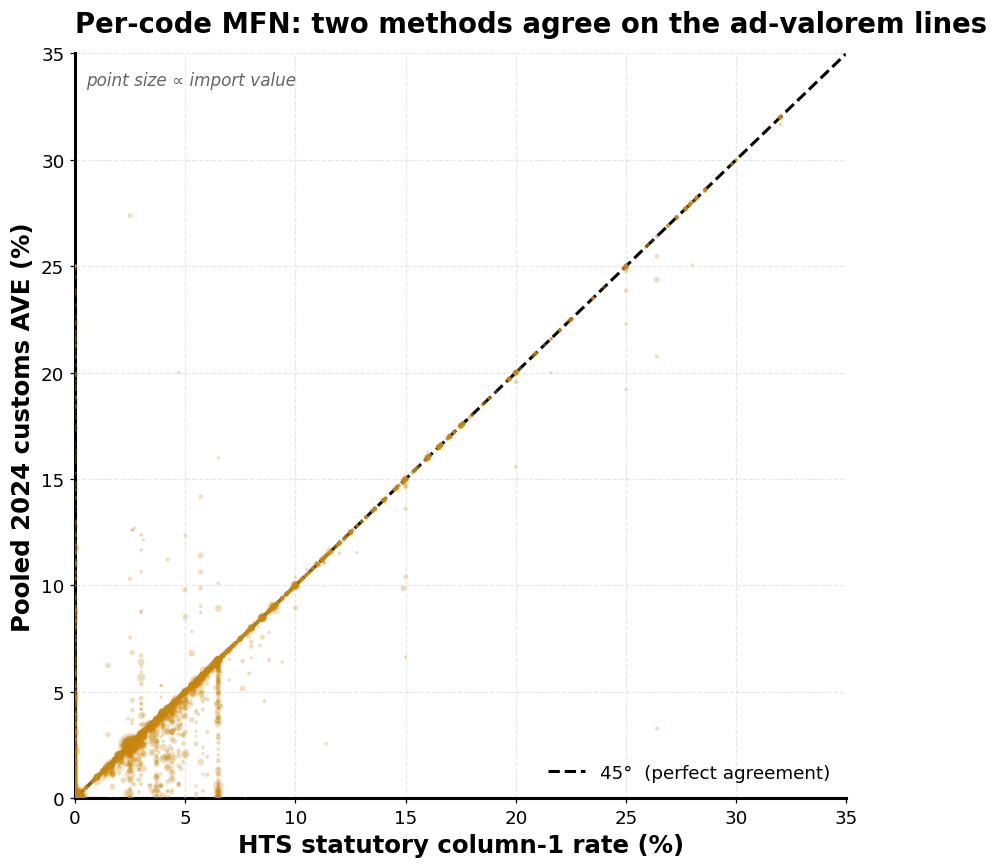

saved figures/mfn-scatter-pooled-vs-hts.png


In [8]:
# Scatter: pooled AVE vs HTS statutory, point size ~ import value (clean lines).
fig, ax = plt.subplots(figsize=(8,8))
s = np.sqrt(clean["imports"]/clean["imports"].max())*300 + 4
ax.scatter(clean["hts_adval"], clean["mfn_pooled_pct"], s=s, alpha=0.28,
           color=PALETTE["pooled"], edgecolor="none", zorder=3)
lim = 35
ax.plot([0,lim],[0,lim], color=PALETTE["ref"], lw=2, ls="--",
        label="45°  (perfect agreement)", zorder=2)
ax.set_xlim(0,lim); ax.set_ylim(0,lim)
ax.set_xlabel("HTS statutory column-1 rate (%)")
ax.set_ylabel("Pooled 2024 customs AVE (%)")
ax.set_title("Per-code MFN: two methods agree on the ad-valorem lines", loc="left", pad=14)
ax.text(0.5, 33.5, "point size ∝ import value", fontsize=11, style="italic", color="0.4")
ax.grid(True); ax.legend(loc="lower right")
fig.tight_layout(); fig.savefig("figures/mfn-scatter-pooled-vs-hts.png")
plt.show()
print("saved figures/mfn-scatter-pooled-vs-hts.png")

## 5. Where the methods diverge — specific & compound duties

On `specific`/`compound` lines the HTS has **no ad-valorem percent** (or only a partial one),
so the statutory table alone cannot cap these codes. The pooled customs AVE *can* —
`duty/value` is defined regardless of how the duty is written. This is the one place the
parquet method is strictly more complete than HTS.

In [9]:
spec = pooled[pooled["hts_type"].isin(["specific","compound"])].copy()
print(f"specific/compound: {len(spec):,} codes, {spec['imports'].sum()/pooled['imports'].sum()*100:.2f}% of trade")
print(f"  trade-wtd pooled AVE on these: {wtd(spec,'mfn_pooled_pct'):.3f}%  (HTS ad-valorem undefined)")
cols = ["HS10","hts_type","hts_raw","mfn_pooled_pct","imports"]
spec.sort_values("imports", ascending=False)[cols].head(10)

specific/compound: 1,311 codes, 3.69% of trade
  trade-wtd pooled AVE on these: 1.953%  (HTS ad-valorem undefined)


,HS10,hts_type,hts_raw,mfn_pooled_pct,imports
2235,2710121550,specific,52.5¢/bbl,0.527588,4.971385e+09
2234,2710121519,specific,52.5¢/bbl,0.505154,3.478189e+09
1921,2204100075,specific,19.8¢/liter,2.171698,1.631124e+09
1929,2204215040,specific,6.3¢/liter,0.655529,1.465254e+09
2238,2710124590,specific,10.5¢/bbl,0.099808,1.359337e+09
1931,2204215055,specific,6.3¢/liter,0.923227,1.324574e+09
1180,1509202090,specific,5¢/kg on contents and container,0.521125,1.132690e+09
15500,9102217010,compound,$1.53 each + 4.2% on the case + 9.8% on the st...,0.153002,1.111116e+09
15503,9102219010,compound,$1.53 each + 4.2% on the case + 2% on the stra...,0.103531,8.238537e+08
2243,2710190635,specific,5.25¢/bbl,0.057820,6.992590e+08


## 6. Recommended combined MFN[code]

**Hybrid rule** — take the exact statutory rate where HTS gives one, fall back to the
pooled customs AVE only where it cannot:

| HTS type | source of MFN | why |
|---|---|---|
| `free`, `advalorem` | HTS statutory % | exact legal MFN |
| `compound` | HTS ad-valorem part **+** pooled excess over that part | keep the specific-duty AVE |
| `specific`, `text`, `other`, `missing` | pooled customs AVE | only estimate available |
| no pooled trade **and** no HTS | 0 | nothing to cap on |

The combined vector is written to `tariff-lists/mfn-per-code.csv` for the cap wiring.

In [10]:
def combined_row(r):
    t = r["hts_type"]
    if t in ("free","advalorem"):
        return r["hts_adval"], f"hts_{t}"
    if t == "compound":
        # ad-valorem part is legal; add any pooled AVE above it as the specific-duty equivalent
        extra = max(0.0, r["mfn_pooled_pct"] - r["hts_adval"])
        return r["hts_adval"] + extra, "hts_compound+pooled"
    # specific / text / other / missing -> pooled AVE
    return r["mfn_pooled_pct"], "pooled"

vals = pooled.apply(combined_row, axis=1)
pooled["mfn_final_pct"] = [v[0] for v in vals]
pooled["mfn_source"]    = [v[1] for v in vals]

out = pooled[["HS10","mfn_final_pct","mfn_source","mfn_pooled_pct","hts_type","hts_adval","imports"]].copy()
out.to_csv("tariff-lists/mfn-per-code.csv", index=False, encoding="utf-8")
print("wrote tariff-lists/mfn-per-code.csv rows:", len(out))
print(out["mfn_source"].value_counts().to_string())
print(f"\ntrade-wtd final MFN: {wtd(pooled,'mfn_final_pct'):.3f}%")

wrote tariff-lists/mfn-per-code.csv rows: 16398
mfn_source
hts_advalorem          8822
hts_free               6210
pooled                  793
hts_compound+pooled     573

trade-wtd final MFN: 1.220%


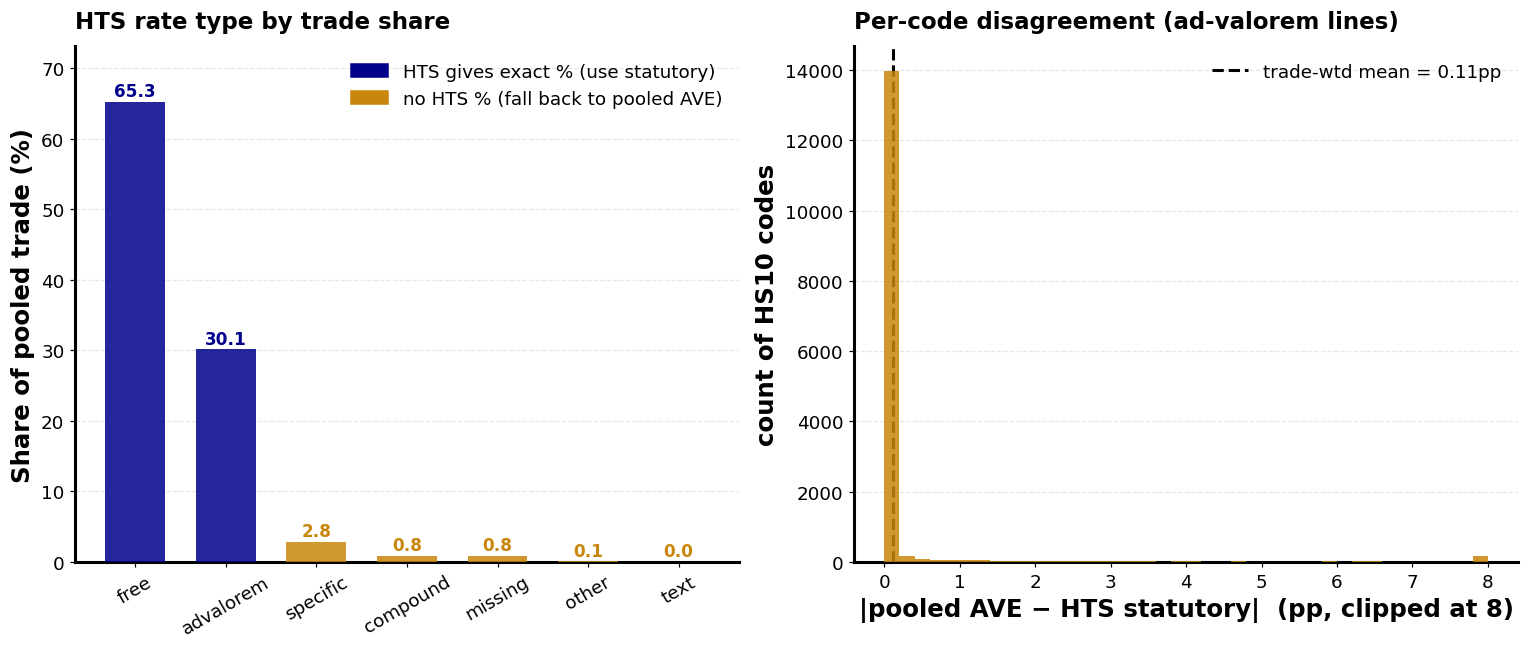

saved figures/mfn-coverage-agreement.png


In [11]:
# Coverage + agreement summary figure
fig, axes = plt.subplots(1, 2, figsize=(14,6))
# (a) trade share by HTS type — the two ad-valorem types in dark blue, the rest in goldenrod
order = cov.index.tolist()
bar_cols = [PALETTE["hts"] if t in ("free","advalorem") else PALETTE["pooled"] for t in order]
b = axes[0].bar(order, cov["trade_share_pct"], color=bar_cols, alpha=0.85, zorder=3, width=0.66)
axes[0].set_ylabel("Share of pooled trade (%)")
axes[0].set_title("HTS rate type by trade share", fontsize=15, loc="left", pad=12)
axes[0].tick_params(axis="x", rotation=30)
axes[0].grid(axis="y")
for i,v in enumerate(cov["trade_share_pct"]):
    axes[0].text(i, v+0.8, f"{v:.1f}", ha="center", fontsize=11, fontweight="bold",
                 color=bar_cols[i])
axes[0].margins(y=0.12)
axes[0].legend(handles=[Patch(color=PALETTE["hts"], label="HTS gives exact % (use statutory)"),
                        Patch(color=PALETTE["pooled"], label="no HTS % (fall back to pooled AVE)")],
               loc="upper right")
# (b) distribution of |pooled - HTS| on clean lines
axes[1].hist(clean["absdiff"].clip(upper=8), bins=40, color=PALETTE["pooled"], alpha=0.85, zorder=3)
axes[1].axvline(wtd(clean,"absdiff"), color=PALETTE["ref"], lw=2, ls="--",
                label=f"trade-wtd mean = {wtd(clean,'absdiff'):.2f}pp")
axes[1].set_xlabel("|pooled AVE − HTS statutory|  (pp, clipped at 8)")
axes[1].set_ylabel("count of HS10 codes")
axes[1].set_title("Per-code disagreement (ad-valorem lines)", fontsize=15, loc="left", pad=12)
axes[1].grid(axis="y"); axes[1].legend(loc="upper right")
fig.tight_layout(); fig.savefig("figures/mfn-coverage-agreement.png")
plt.show()
print("saved figures/mfn-coverage-agreement.png")

## 7. Conclusions & next steps

**Findings**
- On **~95% of trade** (ad-valorem lines) the pooled customs AVE and the HTS statutory rate
  agree to a fraction of a point trade-weighted — the parquet method is validated against
  the exact legal rate.
- On the **~4%** of specific/compound-duty trade the HTS cannot give an ad-valorem number;
  the pooled AVE fills that gap, so the combined vector covers 100% of the labor base.
- The recommended `tariff-lists/mfn-per-code.csv` uses HTS where exact and pooled AVE only
  as a fallback.

**Next steps (for the cap wiring — not done here)**
1. In phase 3 of `make-tariff-by-country-by-time.ipynb`, load `mfn-per-code.csv` and, for the
   five net-of-MFN regimes (EU, Taiwan @10; Japan, Korea, Switzerland @12.5), compute
   `labor_301[code] = max(0, cap − MFN[code])` **per HS10 before weighting**, replacing the
   `MFN=0` flat charge.
2. Decide the **Korea** interpretation explicitly: this vector is *statutory* MFN, so Korea
   gets cap relief (KORUS is a preference, not the MFN). Confirm that matches the notice's
   intent before flipping it on.
3. Re-run the main + overview notebooks; verify the EU's Jul-24 step moves from +0.12pp
   toward the slight fall the FT describes, and refresh the downstream TRI-tracker.